In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
!nvidia-smi
!pip install -q ultralytics==8.4.173

from pathlib import Path
import urllib.request, ultralytics
print("ultralytics", ultralytics.__version__)

try:
    print("internet:", urllib.request.urlopen("https://github.com", timeout=10).status)
except Exception as e:
    print("internet: FAILED ->", e)

hits = list(Path("/kaggle/input").rglob("settings.json"))
assert hits, "checkpoint not found: add the hexovate-checkpoint dataset under Input"
CK = hits[0].parent
print("CHECKPOINT DIR:", CK)
for p in sorted(CK.iterdir()):
    print("  ", p.name)

Tue Oct  6 10:05:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
import os, shutil
from pathlib import Path

try:
    os.makedirs("/kaggle/temp", exist_ok=True)
    ROOT = Path("/kaggle/temp/VisDrone")      # not saved with the notebook output
except Exception:
    ROOT = Path("/tmp/VisDrone")
ROOT.mkdir(parents=True, exist_ok=True)
print("data dir:", ROOT)

base = "https://github.com/ultralytics/assets/releases/download/v0.0.0"
splits = ["train", "val", "test-dev"]

for s in splits:
    f = f"VisDrone2019-DET-{s}.zip"
    !wget -q -P {ROOT} {base}/{f}
    !unzip -q -o {ROOT}/{f} -d {ROOT}
    !rm {ROOT}/{f}
    print("downloaded and unzipped:", s)

# restore the cleaned YOLO-format labels from the checkpoint (Kaggle unpacked them into folders)
for s in splits:
    lab = ROOT / f"VisDrone2019-DET-{s}" / "labels"
    lab.mkdir(exist_ok=True)
    src = CK / f"labels_{s}"
    n = 0
    for p in src.rglob("*.txt"):
        shutil.copy(p, lab / p.name)
        n += 1
    print(f"labels restored for {s}: {n} files")

names_block = """names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor
"""
Path("/kaggle/working").mkdir(exist_ok=True)
Path("/kaggle/working/dataset.yaml").write_text(
    f"path: {ROOT}\ntrain: VisDrone2019-DET-train/images\nval: VisDrone2019-DET-val/images\n"
    f"test: VisDrone2019-DET-test-dev/images\n\n{names_block}")

txt = (CK / "train_oversampled.txt").read_text().replace("/content/VisDrone", str(ROOT))
Path("/kaggle/working/train_oversampled.txt").write_text(txt)
Path("/kaggle/working/dataset_oversampled.yaml").write_text(
    f"path: {ROOT}\ntrain: /kaggle/working/train_oversampled.txt\nval: VisDrone2019-DET-val/images\n"
    f"test: VisDrone2019-DET-test-dev/images\n\n{names_block}")

DATA = "/kaggle/working/dataset.yaml"

for s in splits:
    d = ROOT / f"VisDrone2019-DET-{s}"
    n_img = len(list((d / "images").glob("*.jpg")))
    labs = list((d / "labels").glob("*.txt"))
    n_box = sum(len([l for l in p.read_text().splitlines() if l.strip()]) for p in labs)
    print(f"{s:9s} images={n_img}  label files={len(labs)}  boxes={n_box}")
print("expected: train 6471 images / 343199 boxes, val 548 images / 38759 boxes, test-dev 1610 images")
print("\nDATA yaml:\n", open(DATA).read())

data dir: /kaggle/temp/VisDrone
downloaded and unzipped: train
downloaded and unzipped: val
downloaded and unzipped: test-dev
labels restored for train: 6471 files
labels restored for val: 548 files
labels restored for test-dev: 1610 files
train     images=6471  label files=6471  boxes=343199
val       images=548  label files=548  boxes=38759
test-dev  images=1610  label files=1610  boxes=75101
expected: train 6471 images / 343199 boxes, val 548 images / 38759 boxes, test-dev 1610 images

DATA yaml:
 path: /kaggle/temp/VisDrone
train: VisDrone2019-DET-train/images
val: VisDrone2019-DET-val/images
test: VisDrone2019-DET-test-dev/images

names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor



In [6]:
import time, torch
from ultralytics import YOLO

DATA = "/kaggle/working/dataset.yaml"
print("GPUs:", torch.cuda.device_count(), [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

t0 = time.time()
YOLO("yolo11s.pt").train(
    data=DATA, imgsz=960, batch=8, epochs=1, fraction=0.05,
    device=0, workers=4, seed=0,
    project="/kaggle/working/runs", name="smoke_1gpu", exist_ok=True,
)
print(f"\nTOTAL SMOKE TEST TIME (1 GPU): {time.time() - t0:.0f} s")

GPUs: 2 ['Tesla T4', 'Tesla T4']
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.05, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_1gpu, nbs=64, nms=None,

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


Optimizer stripped from /kaggle/working/runs/smoke_1gpu/weights/best.pt, 19.2MB

Validating /kaggle/working/runs/smoke_1gpu/weights/best.pt...
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,416,670 parameters, 0 gradients, 21.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 1.5it/s 23.4s0.4ss
                   all        548      38759      0.171      0.121      0.104     0.0676
            pedestrian        520       8844     0.0312     0.0017     0.0047    0.00177
                people        482       5125    0.00243    0.00332   0.000493   0.000129
               bicycle        364       1287      0.231      0.049     0.0421     0.0177
                   car        515      14064      0.722      0.516      0.544      0.351
                   van        421       1975     0.0346      0.127     0.0134    0.00764
                 truck

In [9]:
import time, pandas as pd
from ultralytics import YOLO

DATA = "/kaggle/working/dataset.yaml"
names = ["pedestrian", "people", "bicycle", "car", "van",
         "truck", "tricycle", "awning-tricycle", "bus", "motor"]

t0 = time.time()
model = YOLO("yolo11s.pt")
model.train(
    data=DATA, imgsz=960, batch=8, epochs=15,
    device=0, workers=4, seed=0,
    close_mosaic=3,                      # mosaic on for 12 epochs, off for the last 3
    project="/kaggle/working/runs", name="yolo11s_960", exist_ok=True,
)
print(f"\nTRAINING TIME: {(time.time() - t0) / 60:.1f} min")

# final evaluation, same settings as your earlier comparisons (max_det=500, val split)
best = YOLO("/kaggle/working/runs/yolo11s_960/weights/best.pt")
m = best.val(data=DATA, imgsz=960, split="val", max_det=500, batch=16, plots=True,
             project="/kaggle/working/runs", name="yolo11s_960_val", exist_ok=True)

print("\nmAP@50    :", round(m.box.map50, 4))
print("mAP@50-95 :", round(m.box.map, 4))
rows = [{"class": names[c], "AP50": m.box.ap50[i], "AP50-95": m.box.ap[i]}
        for i, c in enumerate(m.box.ap_class_index)]
table = pd.DataFrame(rows).round(3)
print(table)
table.to_csv("/kaggle/working/yolo11s_960_table.csv", index=False)
print("speed (ms/img):", {k: round(v, 1) for k, v in m.speed.items()})

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_960, nbs=64, nms=None, opset=None, optimize=False, opti

In [10]:
import shutil, subprocess
from pathlib import Path
from IPython.display import FileLink, display

# 1. find every best.pt / last.pt in this session
found = subprocess.run(
    "find / \\( -name best.pt -o -name last.pt \\) -not -path '/proc/*' 2>/dev/null",
    shell=True, capture_output=True, text=True).stdout.split()
print("found:", found)

# 2. copy into Output, keeping each run's name so files don't overwrite each other
OUT = Path("/kaggle/working/model_output"); OUT.mkdir(parents=True, exist_ok=True)
for f in found:
    p = Path(f)
    run = p.parent.parent.name              # e.g. yolo11s_960
    dst = OUT / f"{run}_{p.name}"
    shutil.copy(p, dst)
    # also copy the run's training curves if they are next to the weights
    for extra in ["results.csv", "results.png", "args.yaml"]:
        e = p.parent.parent / extra
        if e.exists():
            shutil.copy(e, OUT / f"{run}_{extra}")

# 3. one zip + download links
zip_path = shutil.make_archive("/kaggle/working/model_output", "zip", OUT)
print("\nsaved in Output:")
for f in sorted(Path("/kaggle/working").glob("model_output*")):
    print(" ", f.name)
for f in sorted(OUT.iterdir()):
    print(f"  {f.name}  {f.stat().st_size/1e6:.1f} MB")
display(FileLink("model_output.zip"))

found: ['/kaggle/input/datasets/musfirahather/hexovate-checkpoint/checkpoint_before_yolo11s/runs/baseline_yolo11n/weights/last.pt', '/kaggle/input/datasets/musfirahather/hexovate-checkpoint/checkpoint_before_yolo11s/runs/baseline_yolo11n/weights/best.pt', '/kaggle/input/datasets/musfirahather/hexovate-checkpoint/checkpoint_before_yolo11s/runs/oversampled_yolo11n/weights/last.pt', '/kaggle/input/datasets/musfirahather/hexovate-checkpoint/checkpoint_before_yolo11s/runs/oversampled_yolo11n/weights/best.pt', '/kaggle/working/runs/smoke_1gpu/weights/last.pt', '/kaggle/working/runs/smoke_1gpu/weights/best.pt', '/kaggle/working/runs/yolo11s_960/weights/last.pt', '/kaggle/working/runs/yolo11s_960/weights/best.pt']

saved in Output:
  model_output
  model_output.zip
  baseline_yolo11n_args.yaml  0.0 MB
  baseline_yolo11n_best.pt  5.4 MB
  baseline_yolo11n_last.pt  5.4 MB
  baseline_yolo11n_results.csv  0.0 MB
  baseline_yolo11n_results.png  0.3 MB
  oversampled_yolo11n_args.yaml  0.0 MB
  overs

/kaggle/working/model_output.zip

In [11]:
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

DATA = "/kaggle/working/dataset.yaml"
names = ["pedestrian", "people", "bicycle", "car", "van",
         "truck", "tricycle", "awning-tricycle", "bus", "motor"]
RUN = Path("/kaggle/working/runs/yolo11s_960")

# 1. did training finish, and how did mAP evolve?
r = pd.read_csv(RUN / "results.csv")
r.columns = [c.strip() for c in r.columns]
print("epochs completed:", len(r))
print(r[["epoch", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].round(4).to_string(index=False))

# 2. evaluate best.pt on val (same settings as the earlier models: max_det=500)
best = YOLO(str(RUN / "weights" / "best.pt"))
m = best.val(data=DATA, imgsz=960, split="val", max_det=500, batch=16, plots=True,
             project="/kaggle/working/runs", name="yolo11s_960_val", exist_ok=True)

print("\nmAP@50    :", round(m.box.map50, 4))
print("mAP@50-95 :", round(m.box.map, 4))
table = pd.DataFrame([{"class": names[c], "AP50": m.box.ap50[i], "AP50-95": m.box.ap[i]}
                      for i, c in enumerate(m.box.ap_class_index)]).round(3)
print(table.to_string(index=False))
table.to_csv("/kaggle/working/yolo11s_960_table.csv", index=False)
print("speed (ms/img):", {k: round(v, 1) for k, v in m.speed.items()})

# 3. confusion matrix summary for the new model
cm = m.confusion_matrix.matrix.copy()
a = cm / (cm.sum(0, keepdims=True) + 1e-9)
print("\nShare of true objects: correct vs missed (no detection)")
print(pd.DataFrame({"correct": [a[i, i] for i in range(10)],
                    "missed":  [a[10, i] for i in range(10)]}, index=names).round(3))

epochs completed: 15
 epoch  metrics/mAP50(B)  metrics/mAP50-95(B)
     1            0.3118               0.1769
     2            0.3338               0.1911
     3            0.3567               0.2064
     4            0.3713               0.2195
     5            0.3855               0.2242
     6            0.3999               0.2338
     7            0.4092               0.2409
     8            0.4140               0.2451
     9            0.4385               0.2592
    10            0.4329               0.2578
    11            0.4503               0.2696
    12            0.4547               0.2712
    13            0.4566               0.2726
    14            0.4662               0.2780
    15            0.4663               0.2793
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,416,670 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1603.1±640.4 MB/s, size: 

In [12]:
import shutil
from pathlib import Path
from IPython.display import FileLink, display

OUT = Path("/kaggle/working/model_output"); OUT.mkdir(exist_ok=True)
RUN = Path("/kaggle/working/runs/yolo11s_960")
for f in [RUN/"weights"/"best.pt", RUN/"weights"/"last.pt", RUN/"results.csv", RUN/"results.png", RUN/"args.yaml",
          Path("/kaggle/working/yolo11s_960_table.csv"), Path("/kaggle/working/dataset.yaml")]:
    if f.exists(): shutil.copy(f, OUT / f.name); print("saved:", f.name)
    else: print("MISSING:", f)
shutil.copytree("/kaggle/working/runs/yolo11s_960_val", OUT / "val", dirs_exist_ok=True)
zp = shutil.make_archive("/kaggle/working/model_output", "zip", OUT)
print("zip:", round(Path(zp).stat().st_size / 1e6), "MB")
display(FileLink("model_output.zip"))

saved: best.pt
saved: last.pt
saved: results.csv
saved: results.png
saved: args.yaml
saved: yolo11s_960_table.csv
saved: dataset.yaml
zip: 132 MB


/kaggle/working/model_output.zip

In [15]:
import glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageDraw
from ultralytics import YOLO

hits = (glob.glob("/kaggle/*/VisDrone/VisDrone2019-DET-val/images")
        + glob.glob("/content/VisDrone/VisDrone2019-DET-val/images"))
print("val photos folder:", hits)
assert hits, "Validation photos not found. The session may have been cleared."

val_img_dir = Path(hits[0])
val_lab_dir = val_img_dir.parent / "labels"

MODEL = "/kaggle/working/runs/yolo11s_960/weights/best.pt"
IMGSZ = 960
model = YOLO(MODEL)

CLASS_NAMES = ["pedestrian", "people", "bicycle", "car", "van",
               "truck", "tricycle", "awning-tricycle", "bus", "motor"]


def iou_matrix(a, b):
    """How much do boxes overlap? 1 = perfect match, 0 = no overlap."""
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def read_gt(stem, w, h):
    """Real boxes of one photo, in pixels (left, top, right, bottom)."""
    lines = (val_lab_dir / f"{stem}.txt").read_text().strip().splitlines()
    cls, boxes = [], []
    for l in lines:
        c, xc, yc, bw, bh = l.split()
        xc, yc, bw, bh = float(xc) * w, float(yc) * h, float(bw) * w, float(bh) * h
        cls.append(int(c))
        boxes.append([xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2])
    return np.array(cls), np.array(boxes).reshape(-1, 4)


def score_photo(gc, gb, pc, pb):
    """For each real object say found / wrong / missed. Also count false boxes."""
    outcome = ["missed"] * len(gb)
    fp = len(pb)
    if len(gb) and len(pb):
        iou = iou_matrix(gb, pb)
        for i in range(len(gb)):
            j = iou[i].argmax()
            if iou[i, j] >= 0.5:
                outcome[i] = "found" if pc[j] == gc[i] else "wrong"
        fp = int((iou.max(axis=0) < 0.5).sum())
    return outcome, fp

val photos folder: ['/kaggle/temp/VisDrone/VisDrone2019-DET-val/images']


In [16]:
random.seed(1)
stems = random.sample([p.stem for p in val_img_dir.glob("*.jpg")], 150)

photo_rows, obj_rows = [], []
for stem in stems:
    r = model.predict(str(val_img_dir / f"{stem}.jpg"), imgsz=IMGSZ,
                      conf=0.25, max_det=500, verbose=False)[0]
    pb = r.boxes.xyxy.cpu().numpy()
    pc = r.boxes.cls.cpu().numpy().astype(int)
    h, w = r.orig_shape
    gc, gb = read_gt(stem, w, h)

    outcome, fp = score_photo(gc, gb, pc, pb)
    sizes = np.sqrt((gb[:, 2] - gb[:, 0]) * (gb[:, 3] - gb[:, 1])) if len(gb) else []

    for c, s, o in zip(gc, sizes, outcome):
        obj_rows.append(dict(stem=stem, cls=CLASS_NAMES[c], size=s, outcome=o))
    photo_rows.append(dict(stem=stem, gt=len(gb), missed=outcome.count("missed"),
                           wrong=outcome.count("wrong"), fp=fp))

df_photo = pd.DataFrame(photo_rows)
df_obj = pd.DataFrame(obj_rows)
OUT_COLS = ["found", "wrong", "missed"]

df_obj["size_group"] = pd.cut(df_obj["size"], bins=[0, 16, 32, 96, 10000],
                              labels=["tiny (<16)", "small (16-32)", "medium (32-96)", "large (>96)"])
by_size = pd.crosstab(df_obj["size_group"], df_obj["outcome"], normalize="index").mul(100).round(1)
by_size = by_size.reindex(columns=OUT_COLS, fill_value=0)
by_size["objects"] = df_obj["size_group"].value_counts()
print("Result by object size (% of objects):\n", by_size)

by_class = (pd.crosstab(df_obj["cls"], df_obj["outcome"], normalize="index")
            .mul(100).round(1).reindex(columns=OUT_COLS, fill_value=0).reindex(CLASS_NAMES))
print("\nResult by class (% of objects):\n", by_class)

Result by object size (% of objects):
 outcome         found  wrong  missed  objects
size_group                                   
tiny (<16)       28.6    7.6    63.9     3264
small (16-32)    58.8   10.1    31.0     3894
medium (32-96)   79.2    9.2    11.6     3067
large (>96)      89.2    9.0     1.8      277

Result by class (% of objects):
 outcome          found  wrong  missed
cls                                  
pedestrian        50.5    4.2    45.3
people            34.1   11.4    54.5
bicycle           22.7   22.7    54.7
car               80.2    2.5    17.3
van               39.8   41.3    19.0
truck             42.1   16.5    41.4
tricycle          27.9   19.0    53.0
awning-tricycle   25.5   33.3    41.2
bus               43.8   14.1    42.2
motor             51.6    8.5    39.9


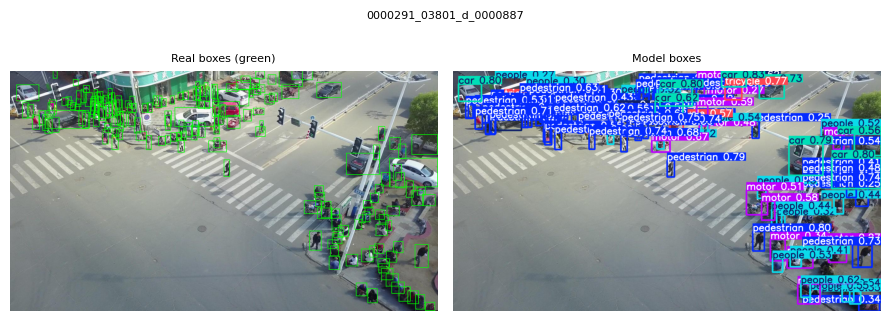

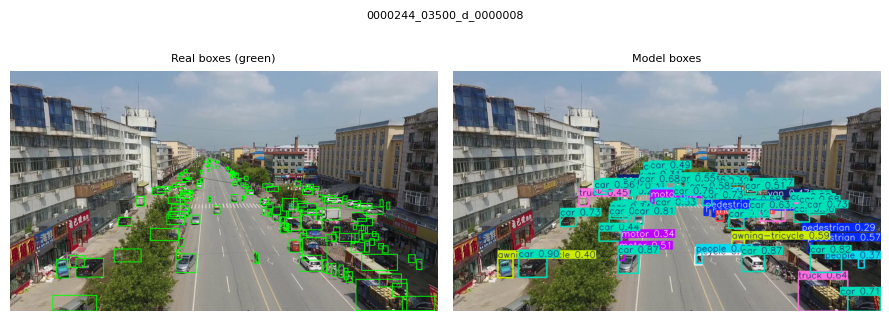

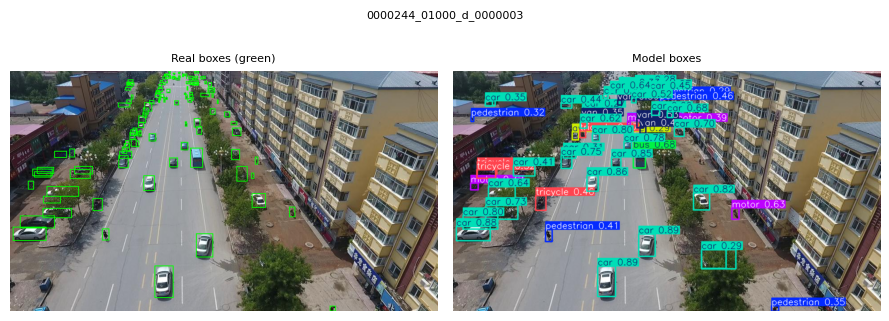

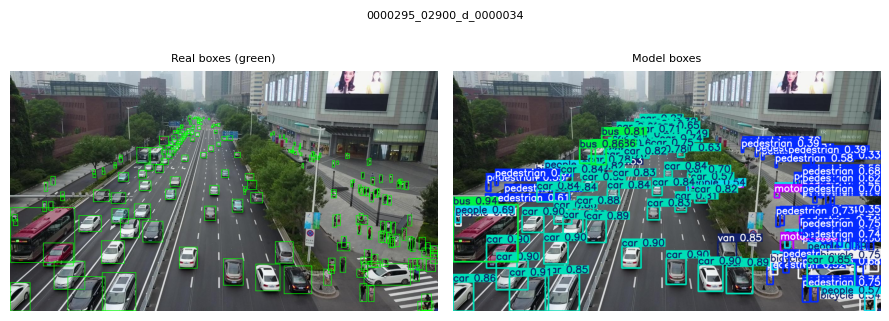

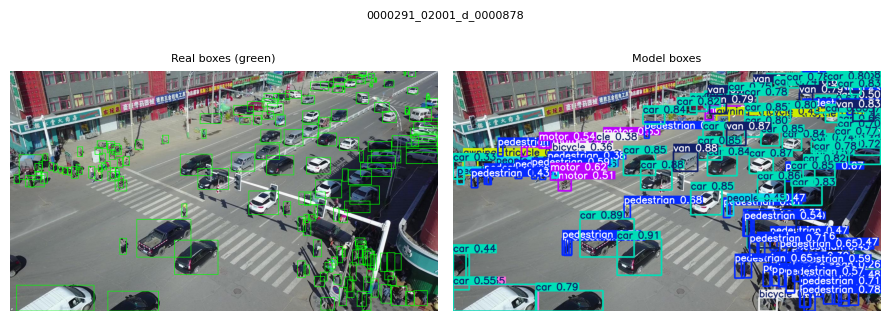

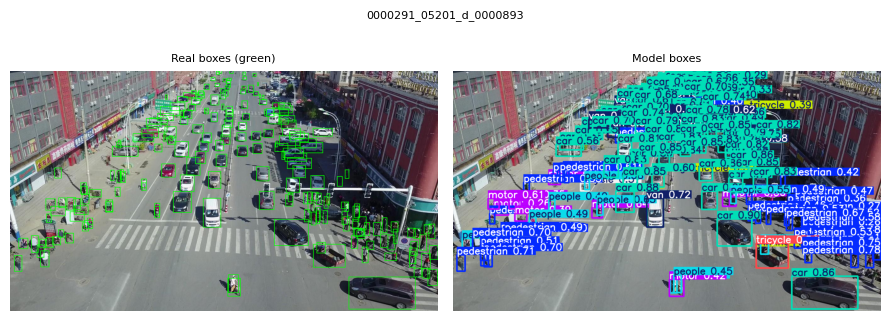

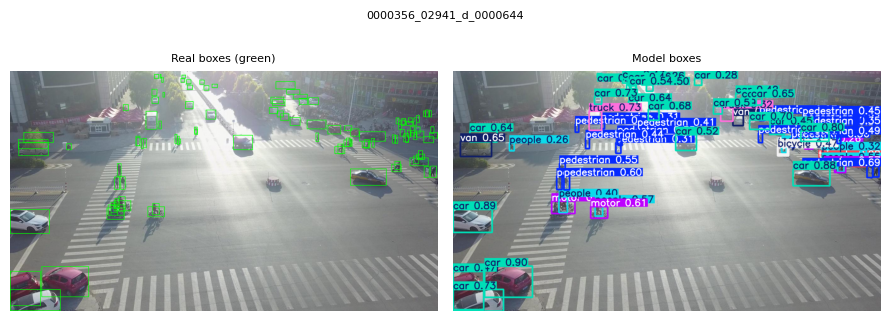

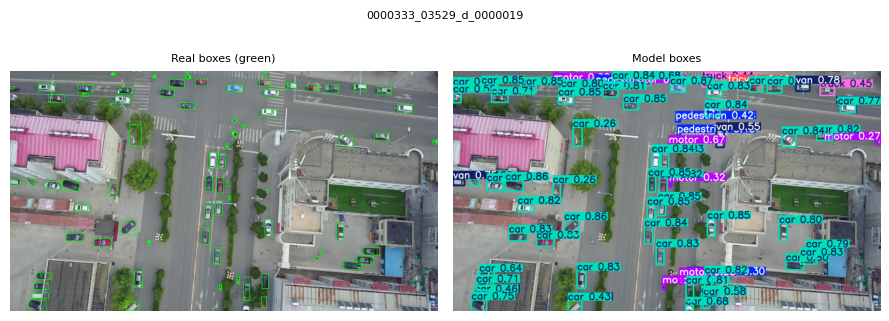

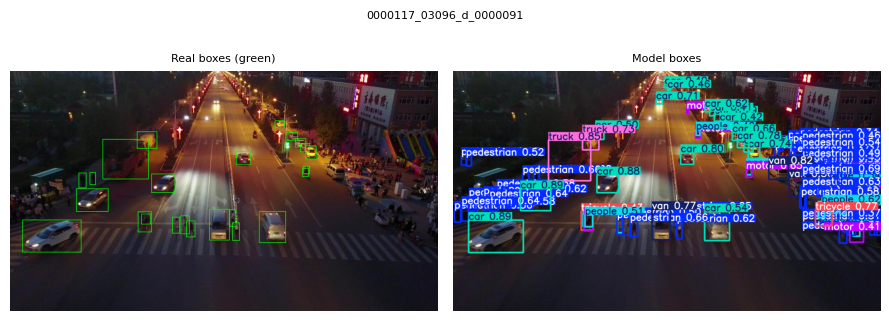

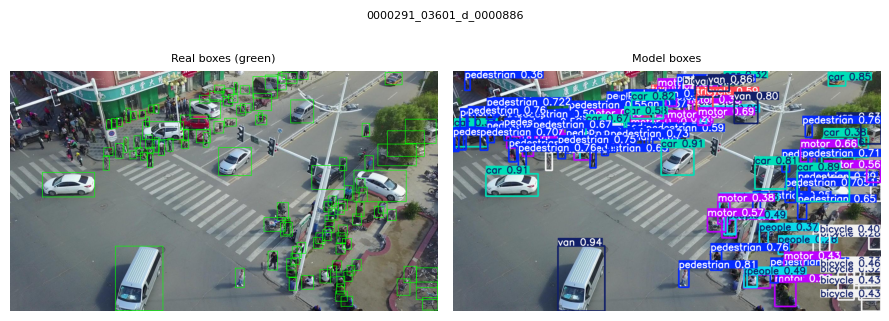

                        stem   gt  missed  wrong  fp
26   0000291_02001_d_0000878  172      63     22  29
28   0000333_03529_d_0000019   95      29     18   7
43   0000291_03601_d_0000886  112      43     14  55
46   0000291_05201_d_0000893  207      71     20  34
47   0000117_03096_d_0000091   24       0      2  68
57   0000295_02900_d_0000034  212      79      4  15
71   0000244_01000_d_0000003  122      81      6  14
98   0000356_02941_d_0000644  108      51     20   9
126  0000244_03500_d_0000008  146      90      8   7
148  0000291_03801_d_0000887  191     102     14  20


In [17]:
picked = []
for col in ["missed", "wrong", "fp"]:
    picked += list(df_photo.sort_values(col, ascending=False).stem[:4])
picked = list(dict.fromkeys(picked))[:10]

out_dir = Path("/kaggle/working/keep/failures")
out_dir.mkdir(parents=True, exist_ok=True)

for stem in picked:
    img = Image.open(val_img_dir / f"{stem}.jpg").convert("RGB")

    gt_img = img.copy()
    draw = ImageDraw.Draw(gt_img)
    gc, gb = read_gt(stem, img.width, img.height)
    for b in gb:
        draw.rectangle([float(v) for v in b], outline="lime", width=2)

    r = model.predict(img, imgsz=IMGSZ, conf=0.25, max_det=500, verbose=False)[0]
    pred_img = Image.fromarray(r.plot()[:, :, ::-1])

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    axes[0].imshow(gt_img);   axes[0].set_title("Real boxes (green)", fontsize=8)
    axes[1].imshow(pred_img); axes[1].set_title("Model boxes", fontsize=8)
    for a in axes:
        a.axis("off")
    fig.suptitle(stem, fontsize=8)
    plt.tight_layout()
    plt.savefig(out_dir / f"{stem}.png", dpi=110)
    plt.show()

print(df_photo[df_photo.stem.isin(picked)])
df_photo.to_csv(out_dir / "failure_scan.csv", index=False)
by_size.to_csv(out_dir / "miss_by_size.csv")
by_class.to_csv(out_dir / "result_by_class.csv")

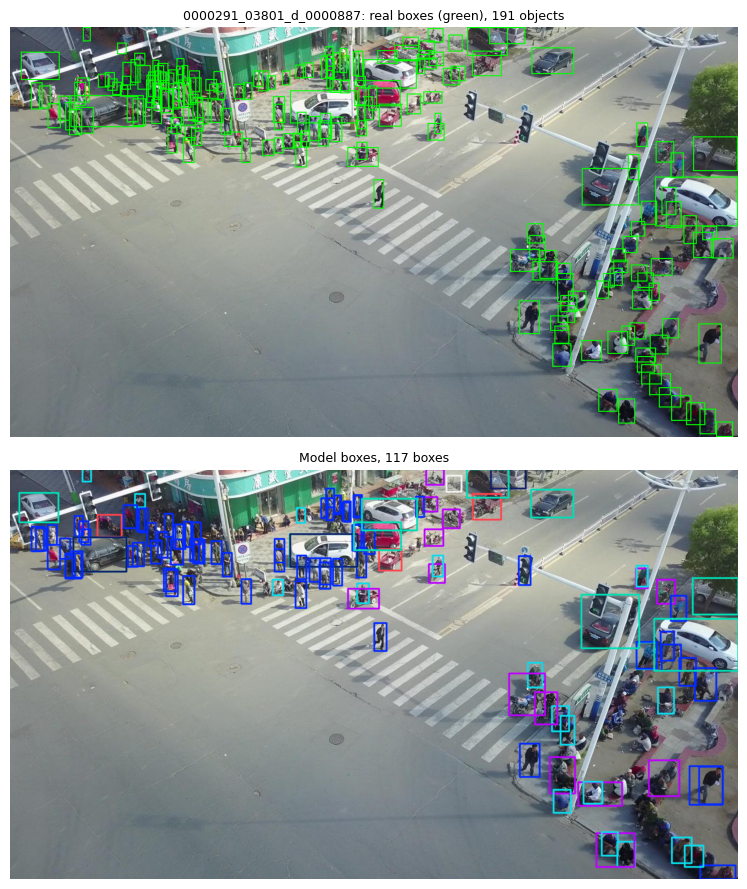

In [18]:
i = 0   # change to 1, 2, 3 ... to see the other photos
stem = picked[i]

img = Image.open(val_img_dir / f"{stem}.jpg").convert("RGB")
gc, gb = read_gt(stem, img.width, img.height)

gt_img = img.copy()
d = ImageDraw.Draw(gt_img)
for b in gb:
    d.rectangle([float(v) for v in b], outline="lime", width=2)

r = model.predict(img, imgsz=IMGSZ, conf=0.25, max_det=500, verbose=False)[0]
pred_img = Image.fromarray(r.plot(labels=False, conf=False, line_width=2)[:, :, ::-1])

fig, axes = plt.subplots(2, 1, figsize=(8, 9))
axes[0].imshow(gt_img);   axes[0].set_title(f"{stem}: real boxes (green), {len(gb)} objects", fontsize=9)
axes[1].imshow(pred_img); axes[1].set_title(f"Model boxes, {len(r.boxes)} boxes", fontsize=9)
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

In [19]:
from collections import Counter


def explain(stem):
    r = model.predict(str(val_img_dir / f"{stem}.jpg"), imgsz=IMGSZ,
                      conf=0.25, max_det=500, verbose=False)[0]
    pb = r.boxes.xyxy.cpu().numpy()
    pc = r.boxes.cls.cpu().numpy().astype(int)
    h, w = r.orig_shape
    gc, gb = read_gt(stem, w, h)

    n_gt, n_pred = len(gb), len(pb)
    sizes = np.sqrt((gb[:, 2] - gb[:, 0]) * (gb[:, 3] - gb[:, 1])) if n_gt else np.array([])
    outcome, fp = score_photo(gc, gb, pc, pb)
    missed_idx = [i for i, o in enumerate(outcome) if o == "missed"]
    n_missed, n_wrong = len(missed_idx), outcome.count("wrong")
    tiny_share = float((sizes[missed_idx] < 32).mean()) if n_missed else 0.0

    confusions = Counter()
    if n_gt and n_pred:
        iou = iou_matrix(gb, pb)
        for i, o in enumerate(outcome):
            if o == "wrong":
                confusions[(CLASS_NAMES[gc[i]], CLASS_NAMES[pc[iou[i].argmax()]])] += 1

    reasons = []
    if n_gt >= 100:
        reasons.append(f"very crowded scene ({n_gt} real objects), boxes overlap and merge")
    if n_missed >= 0.3 * max(n_gt, 1) and tiny_share >= 0.8:
        reasons.append(f"most missed objects are tiny (under 32 px: {tiny_share:.0%} of the misses)")
    if n_wrong >= 0.15 * max(n_gt, 1) and confusions:
        (t, p), n = confusions.most_common(1)[0]
        reasons.append(f"many wrong classes, most often real {t} called {p} ({n} times)")
    if fp >= 0.3 * max(n_gt, 1):
        reasons.append(f"many extra boxes ({fp}) with no matching label")
    if not reasons:
        reasons.append("no clear pattern from the numbers, look at the picture")

    print(f"{stem}: real {n_gt}, model boxes {n_pred}, missed {n_missed}, wrong class {n_wrong}, extra boxes {fp}")
    if confusions:
        print("   top mix-ups:", [(f"{t}->{p}", n) for (t, p), n in confusions.most_common(2)])
    print("   draft reason:", "; ".join(reasons))


for stem in picked:
    explain(stem)

0000291_03801_d_0000887: real 191, model boxes 117, missed 102, wrong class 14, extra boxes 20
   top mix-ups: [('tricycle->pedestrian', 7), ('pedestrian->people', 3)]
   draft reason: very crowded scene (191 real objects), boxes overlap and merge
0000244_03500_d_0000008: real 146, model boxes 75, missed 90, wrong class 8, extra boxes 7
   top mix-ups: [('van->car', 4), ('truck->car', 2)]
   draft reason: very crowded scene (146 real objects), boxes overlap and merge; most missed objects are tiny (under 32 px: 92% of the misses)
0000244_01000_d_0000003: real 122, model boxes 56, missed 81, wrong class 6, extra boxes 14
   top mix-ups: [('truck->car', 2), ('van->car', 1)]
   draft reason: very crowded scene (122 real objects), boxes overlap and merge; most missed objects are tiny (under 32 px: 100% of the misses)
0000295_02900_d_0000034: real 212, model boxes 157, missed 79, wrong class 4, extra boxes 15
   top mix-ups: [('tricycle->motor', 1), ('people->pedestrian', 1)]
   draft reason

In [23]:
import shutil, zipfile
from pathlib import Path

W = Path("/kaggle/working")

def folder_size(p):
    p = Path(p)
    if p.is_file():
        return p.stat().st_size
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.exists() else 0

def show_disk(tag):
    u = shutil.disk_usage(W)
    print(tag, "| total GB:", round(u.total / 1e9, 1), "used GB:", round(u.used / 1e9, 1), "free GB:", round(u.free / 1e9, 2))

show_disk("before")

# what is using the space in /kaggle/working
items = sorted(((folder_size(p), p.name) for p in W.iterdir()), reverse=True)
print("biggest items in /kaggle/working:")
for s, n in items[:12]:
    print("  ", round(s / 1e6, 1), "MB ", n)
for extra in ["/kaggle/temp", "/tmp"]:
    print("   (", extra, "is", round(folder_size(extra) / 1e9, 2), "GB )")

# safe cleanup only: half-built export, smoke tests, pip cache
for p in [W / "project_export", W / "runs/smoke_1gpu", W / "runs/smoke_2gpu"]:
    if p.exists():
        shutil.rmtree(p, ignore_errors=True)
        print("removed:", p.name)
!pip cache purge -q
show_disk("after cleanup")

# files to include (taken directly from their original locations)
RUN = W / "runs/yolo11s_960"
VAL = W / "runs/yolo11s_960_val"
files = []
def add(path, arc):
    path = Path(path)
    if path.is_file():
        files.append((path, arc))
    elif path.is_dir():
        for f in path.rglob("*"):
            if f.is_file():
                files.append((f, str(Path(arc) / f.relative_to(path))))
    else:
        print("MISSING:", path)

add(RUN / "weights/best.pt", "weights/best.pt")
add(RUN / "weights/last.pt", "weights/last.pt")
for n in ["results.csv", "results.png", "args.yaml", "labels.jpg"]:
    add(RUN / n, "train/" + n)
add(VAL, "val")
add(W / "failures", "failure_examples")
add(W / "backup", "backup")
for pat in ["*.csv", "*.png", "*.npy", "*.npz", "*.yaml", "*.json"]:
    for f in W.glob(pat):
        add(f, "results/" + f.name)

need = sum(f.stat().st_size for f, _ in files)
free = shutil.disk_usage(W).free
print("to zip:", round(need / 1e6), "MB in", len(files), "files | free:", round(free / 1e6), "MB")

if need * 1.05 + 50e6 > free:
    print("NOT ENOUGH SPACE for the zip. Paste the lists above and do not close the session.")
else:
    zp = W / "hexovate_project_export.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        for f, arc in files:
            z.write(f, arc)
        z.writestr("RESULTS.md", """# Hexovate Task 2: VisDrone, export summary
Val (548 images / 38,759 boxes, max_det=500):
- YOLO11n @640 baseline: mAP50 0.2408, mAP50-95 0.1339
- YOLO11n @640 oversampled: mAP50 0.2422, mAP50-95 0.1340
- YOLO11s @960, 15 epochs: mAP50 0.4628, mAP50-95 0.2785 (13.5 ms/img on T4)
Limits: not a controlled comparison (model, size, epochs, mosaic changed together); single seed;
oversampling made no meaningful difference; test-dev not run.
Not done: dashboard, written failure explanations, tiled inference, README/write-up.
""")
    with zipfile.ZipFile(zp) as z:
        names_in = z.namelist()
    print("ZIP:", zp.name, round(zp.stat().st_size / 1e6), "MB,", len(names_in), "files")
    print("best.pt included:", "weights/best.pt" in names_in)
    from IPython.display import FileLink, display
    display(FileLink("hexovate_project_export.zip"))

before | total GB: 21.0 used GB: 20.9 free GB: 0.0
biggest items in /kaggle/working:
   20538.1 MB  kaggle_backup.zip
   143.6 MB  model_output
   131.7 MB  model_output.zip
   97.4 MB  runs
   19.3 MB  yolo11s.pt
   5.5 MB  weights
   3.5 MB  keep
   1.1 MB  train_oversampled.txt
   0.0 MB  .virtual_documents
   0.0 MB  dataset_oversampled.yaml
   0.0 MB  dataset.yaml
   0.0 MB  yolo11s_960_table.csv
   ( /kaggle/temp is 1.98 GB )
   ( /tmp is 0.0 GB )
removed: smoke_1gpu
after cleanup | total GB: 21.0 used GB: 20.9 free GB: 0.04
MISSING: /kaggle/working/failures
MISSING: /kaggle/working/backup
to zip: 44 MB in 21 files | free: 45 MB
NOT ENOUGH SPACE for the zip. Paste the lists above and do not close the session.


In [24]:
from IPython.display import FileLink, display
display(FileLink("model_output.zip"))

/kaggle/working/model_output.zip